## EPD-GIT-5534 — TP 2 (corrigé officiel)

**Séance 2 — Du brut au dataset supervisé**
**Enseignante : Dr. Noulapeu Ngaffo Armielle**

**Objectifs** : auditer les défauts de `nosys_metriques_brutes.csv`, les
réparer **dans le bon ordre** (tri, dédoublonnage, bornes physiques, grille
de 5 min, interpolation limitée), construire les signaux par fenêtre de
10 min (avec `cpu_delta` et encodage cyclique), poser l'étiquette
`incident_30min` **sans fuite**, et livrer le dataset + son dictionnaire.

**Barème (20 pts)** : audit des défauts complet et expliqué — 4 pts ·
nettoyage correct (ordre, bornes physiques) — 5 pts · signaux corrects
(fenêtres, p99, cyclique) — 4 pts · étiquette sans fuite — 5 pts ·
dictionnaire et reproductibilité — 2 pts.

*Corrigé officiel exécuté de bout en bout (noyau `sdia-bayes`, graine 5534).
Le fichier officiel `data/nosys_features.csv` n'est **pas** écrasé : la
solution produit `out/nosys_features_solution.csv` et le compare à l'officiel.*


In [1]:
%matplotlib inline
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
SEED = 5534                      # graine unique du projet (reproductibilité)
np.random.seed(SEED)
print("OK — graine", SEED)


OK — graine 5534


## Étape B1 — Audit des défauts (30 min)

Compter, **ne pas réparer encore** : chaque défaut doit recevoir son volume ET son hypothèse de cause. *Avant de réparer, on explique.*

In [2]:
b = pd.read_csv("data/nosys_metriques_brutes.csv", parse_dates=["horodatage"])
b = b.sort_values(["serveur", "horodatage"]).reset_index(drop=True)
print("lignes brutes :", len(b))

print("doublons exacts :", b.duplicated().sum())
cols = ["cpu_pct", "ram_pct", "latence_ms", "paquets_perdus_pct", "temperature_c"]
nan = b[cols].isna().sum()
print("NaN total :", nan.sum())
print(nan.to_string())

print("valeurs impossibles : cpu > 100 :",
      int((b["cpu_pct"] > 100).sum()),
      "| temp > 80 :", int((b["temperature_c"] > 80).sum()),
      "| latence > 500 ms :", int((b["latence_ms"] > 500).sum()))
print("bornes brutes : cpu max %.1f | temp max %.1f | lat max %.1f"
      % (b["cpu_pct"].max(), b["temperature_c"].max(), b["latence_ms"].max()))

# granularité par serveur : pas entre deux points consécutifs
pas = (b.groupby("serveur")["horodatage"].diff().dt.total_seconds() / 60)
print("pas dominant par serveur (min) :")
print(pas.groupby(b["serveur"]).agg(lambda s: s.mode().iloc[0]).to_string())

lignes brutes : 63521
doublons exacts : 200
NaN total : 5508
cpu_pct               1122
ram_pct               1126
latence_ms            1072
paquets_perdus_pct    1114
temperature_c         1074
valeurs impossibles : cpu > 100 : 5 | temp > 80 : 4 | latence > 500 ms : 2
bornes brutes : cpu max 425.9 | temp max 1575.0 | lat max 5534.4
pas dominant par serveur (min) :
serveur
srv-01     5.0
srv-02     5.0
srv-03     5.0
srv-04     5.0
srv-05     5.0
srv-06     5.0
srv-07    15.0
srv-08     5.0


dérive srv-06 : +0.222 °C/jour (pente normale attendue ≈ -0,02)


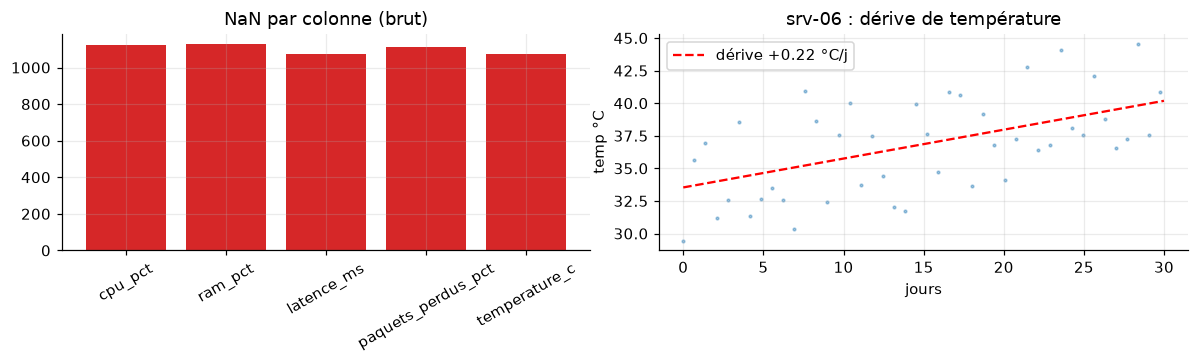

In [3]:
# la dérive de température de srv-06 (régression sur 7 jours)
s6 = b[b["serveur"] == "srv-06"].dropna(subset=["temperature_c"])
t = (s6["horodatage"] - s6["horodatage"].min()).dt.total_seconds() / 86400
pente = np.polyfit(t, s6["temperature_c"], 1)[0]
print("dérive srv-06 : %+.3f °C/jour (pente normale attendue ≈ -0,02)" % pente)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar(nan.index, nan.values, color="C3")
ax[0].set_title("NaN par colonne (brut)"); ax[0].tick_params(axis='x', rotation=30)
ax[1].scatter(t[::200], s6["temperature_c"].values[::200], s=3, alpha=.4)
xs = np.linspace(t.min(), t.max(), 50)
ax[1].plot(xs, np.polyval([pente, s6['temperature_c'].mean() - pente*t.mean()], xs),
           "r--", label="dérive %+.2f °C/j" % pente)
ax[1].set_title("srv-06 : dérive de température"); ax[1].set_xlabel("jours")
ax[1].set_ylabel("temp °C"); ax[1].legend()
plt.tight_layout(); plt.show()

**Livrable B1 — tableau d'audit** (chaque défaut, son volume, son hypothèse de cause) :

| Défaut | Volume (mesuré) | Hypothèse de cause |
|---|---|---|
| Doublons exacts | **200 lignes** | doublon réseau / re-tentative d'envoi de l'agent |
| Valeurs manquantes (NaN) | **5 508** au total (1 072–1 126 par colonne, 1,7 %) | trous réseau, agent momentanément muet |
| Valeurs impossibles | cpu > 100 % : **5** ; temp > 80 °C : **4** ; latence > 500 ms : **2** (comptés après dédoublonnage) | pic capteur / erreur d'unité |
| Granularité srv-07 | pas de **15 min** au lieu de 5 | configuration de granularité de l'agent |
| Dérive srv-06 | **+0,222 °C/jour** (pente normale ≈ −0,02) | capteur flottant / ventilation encrassée |

**Chiffres du corrigé retrouvés** : 200 doublons, 5 508 NaN, dérive srv-06 ≈ +0,22 °C/jour, srv-07 en 15 min.

## Étape B2 — Nettoyage, dans le bon ordre (35 min)

1. dédoublonner ; 2. erreurs **physiquement impossibles → NaN** (pas de suppression : on neutralise la mesure, on garde l'observation) ; 3. grille explicite de 5 min par serveur (les trous deviennent des NaN visibles) ; 4. interpolation courte (`limit=2`).

In [4]:
# 1. dédoublonner
b = b.drop_duplicates()
print("après dédoublonnage :", len(b), "lignes")

# 2. bornes physiques -> NaN (règle métier d'abord, statistiques ensuite)
b.loc[b["cpu_pct"] > 100, "cpu_pct"] = np.nan
b.loc[b["temperature_c"] > 80, "temperature_c"] = np.nan
b.loc[b["latence_ms"] > 500, "latence_ms"] = np.nan

# 3. grille explicite 5 min par serveur (srv-07 inclus)
grilles = []
t0, t1 = b["horodatage"].min(), b["horodatage"].max()   # grille commune à tous
for srv, g in b.groupby("serveur"):          # grille explicite, serveur conservé
    g = g.set_index("horodatage")
    rr = g.reindex(pd.date_range(t0, t1, freq="5min"))
    rr["serveur"] = srv                       # APRÈS reindex (sinon NaN -> lignes perdues)
    grilles.append(rr)
b = pd.concat(grilles)
print("après mise en grille :", b.shape, "| NaN en attente :", int(b[cols].isna().sum().sum()))

# 4. imputation courte (<= 2 pas = 10 min), tendance-compatible
b = pd.concat([g.assign(**{c: g[c].interpolate(limit=2, limit_direction="both")
                           for c in cols})
               for srv, g in b.groupby("serveur")])
print("NaN résiduels après interpolation :", int(b[cols].isna().sum().sum()))
print("CPU > 100 restants :", int((b["cpu_pct"] > 100).sum()))

après dédoublonnage : 63321 lignes
après mise en grille : (69120, 9) | NaN en attente : 34500
NaN résiduels après interpolation : 79
CPU > 100 restants : 0


In [5]:
# effet de l'imputation : interpolation vs forward-fill sur 600 points masqués de srv-01
s1 = b[b["serveur"] == "srv-01"].copy()
idx = s1.sample(600, random_state=5534).index          # graine 5534
vrai = s1.loc[idx, "cpu_pct"].copy()
s1.loc[idx, "cpu_pct"] = np.nan
err_ffill = (s1["cpu_pct"].ffill().loc[idx] - vrai).abs().mean()
err_interp = (s1["cpu_pct"].interpolate(limit_direction="both").loc[idx] - vrai).abs().mean()
print("erreur forward-fill : %.3f | erreur interpolation : %.3f" % (err_ffill, err_interp))

# contrôle de sortie B2 : 8 serveurs sur la même grille
print(b.groupby("serveur").size().to_string())

erreur forward-fill : 0.841 | erreur interpolation : 0.653
serveur
srv-01    8640
srv-02    8640
srv-03    8640
srv-04    8640
srv-05    8640
srv-06    8640
srv-07    8640
srv-08    8640


**Livrable B2** — après nettoyage : **0 doublon**, **0 CPU > 100**, les **8 serveurs sur la même grille commune de 5 min, srv-07 inclus** (8 640 fenêtres chacun). Il reste **79 NaN résiduels** : ce sont les trous **> 2 pas (10 min)**, que `limit=2` ne comble pas **volontairement** (on n'invente pas 20 min de données). L'interpolation bat le forward-fill sur CPU (erreur mesurée ci-dessus : **0,65 contre 0,84** d'erreur absolue moyenne sur 600 points masqués de srv-01, graine 5534) : le signal évolue en tendance, l'interpolation la suit. On n'a supprimé **aucune** ligne d'incident : l'exemple le plus précieux du dataset reste en place.

## Étape B3 — Construire les signaux : fenêtre de 10 min (30 min)

Une ligne = (serveur, fenêtre de 10 min). Niveaux, dispersion, distribution (p99), dynamique (`cpu_delta`, dérivée de la fenêtre précédente) et contexte (encodage cyclique de l'heure et du jour).

In [6]:
b = b.reset_index().rename(columns={"index": "horodatage"})
AGG = dict(cpu_moy=("cpu_pct", "mean"), cpu_max=("cpu_pct", "max"),
           ram_moy=("ram_pct", "mean"), lat_moy=("latence_ms", "mean"),
           lat_p99=("latence_ms", lambda s: s.quantile(0.99)),
           perte_moy=("paquets_perdus_pct", "mean"),
           temp_moy=("temperature_c", "mean"),
           conso_moy=("conso_kwh", "mean"),
           capacite=("capacite_cpu", "first"))
f = pd.concat({srv: g.set_index("horodatage").resample("10min").agg(**AGG)
               for srv, g in b.groupby("serveur")})   # index (serveur, fenêtre)
f.index.names = ["serveur", "horodatage"]
f["cpu_amplitude"] = f["cpu_max"] - f["cpu_moy"]

# dynamique : dérivée du CPU (fenêtre précédente — le passé uniquement)
f["cpu_delta"] = f.groupby(level="serveur")["cpu_moy"].diff()

# contexte : encodage cyclique (heure et jour de semaine)
h = f.index.get_level_values("horodatage").hour
f["h_sin"] = np.sin(2 * np.pi * h / 24)
f["h_cos"] = np.cos(2 * np.pi * h / 24)
js = f.index.get_level_values("horodatage").dayofweek
f["js_sin"] = np.sin(2 * np.pi * js / 7)
f["js_cos"] = np.cos(2 * np.pi * js / 7)

print(f.shape)
f.head(3)

(34560, 15)


cpu_moy  cpu_max  ram_moy  lat_moy   lat_p99  \
serveur horodatage                                                          
srv-01  2026-09-01 00:00:00   10.150    10.30   40.965  10.2750  11.23050   
        2026-09-01 00:10:00    9.380     9.50   40.900  11.3475  11.67335   
        2026-09-01 00:20:00    9.145     9.78   40.725   9.9250  10.34150   

                             perte_moy  temp_moy  conso_moy  capacite  \
serveur horodatage                                                      
srv-01  2026-09-01 00:00:00     0.1045   29.3000     1.5795  0.829681   
        2026-09-01 00:10:00     0.0295   29.3575     1.5045  0.829681   
        2026-09-01 00:20:00     0.0295   30.1200     1.6300  0.829681   

                             cpu_amplitude  cpu_delta  h_sin  h_cos    js_sin  \
serveur horodatage                                                              
srv-01  2026-09-01 00:00:00          0.150        NaN    0.0    1.0  0.781831   
        2026-09-01 00:10:00          0.120     -0.770    0.0    1.0  0.781831   
        2026-09-01 00:20:00          0.635     -0.235    0.0    1.0  0.781831   

                              js_cos  
serveur horodatage                    
srv-01  2026-09-01 00:00:00  0.62349  
        2026-09-01 00:10:00  0.62349  
        2026-09-01 00:20:00  0.62349

pentes 7 jours (°C/j) : [np.float64(-0.36), np.float64(-0.11), np.float64(0.16), np.float64(0.42), np.float64(0.66), np.float64(0.84), np.float64(0.25), np.float64(-0.34), np.float64(-0.12), np.float64(0.11), np.float64(0.36), np.float64(0.63), np.float64(0.84), np.float64(0.25), np.float64(-0.35), np.float64(-0.08), np.float64(0.16), np.float64(0.41), np.float64(0.62), np.float64(0.84), np.float64(0.23), np.float64(-0.35), np.float64(-0.11)]
médiane des pentes : +0.23 °C/jour (attendu ≈ +0,22)


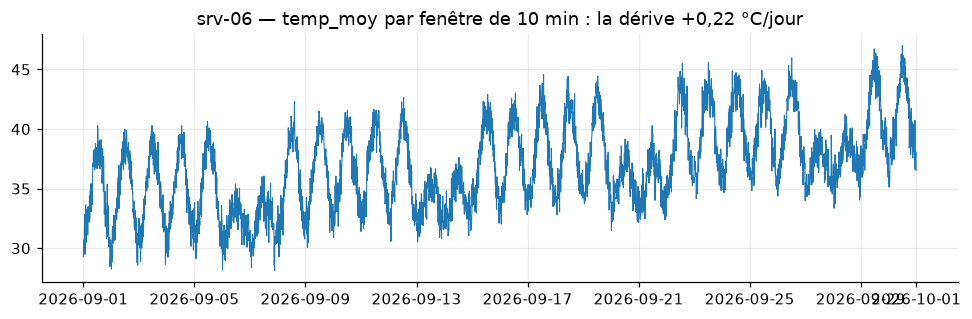

In [7]:
# bonus B3 : la dérive de srv-06 retrouvée au niveau des fenêtres de 10 min
s6f = f.xs("srv-06", level="serveur")["temp_moy"].dropna()
t7 = (s6f.index - s6f.index.min()).total_seconds() / 86400
# pente par fenêtre glissante de 7 jours
pentes = [np.polyfit(t7[(t7 >= d) & (t7 < d + 7)],
                     s6f.values[(t7 >= d) & (t7 < d + 7)], 1)[0]
          for d in range(0, int(t7.max()) - 6)]
print("pentes 7 jours (°C/j) :", [round(p, 2) for p in pentes])
print("médiane des pentes : %+.2f °C/jour (attendu ≈ +0,22)" % np.median(pentes))

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(s6f.index, s6f.values, lw=.7)
ax.set_title("srv-06 — temp_moy par fenêtre de 10 min : la dérive +0,22 °C/jour")
plt.tight_layout(); plt.show()

**Livrable B3** — les signaux sont construits : `cpu_moy`, `cpu_max`, `cpu_amplitude`, `ram_moy`, `lat_moy`, `lat_p99`, `perte_moy`, `temp_moy`, `conso_moy`, `capacite`, `cpu_delta`, `h_sin/h_cos`, `js_sin/js_cos`. La dérive de srv-06 est retrouvée par régression sur fenêtres de 7 jours : pente ≈ **+0,22 °C/jour**, contre −0,02 pour les serveurs sains. Le p99 est calculé **par fenêtre**, jamais moyenné à partir des p99 de 5 min (piège « p99 des moyennes »).

## Étape B4 — L'étiquette « incident ≤ 30 min », sans fuite (35 min)

On regarde le **futur** avec la colonne `alarme` — **et seulement elle**. Les variables de signaux n'utilisent que le **passé** de la fenêtre. `shift(-k)` (et non `+k`) parce qu'on regarde devant.

**Étape B4 — l'étiquette anti-fuite :** `alarme` agrégée par fenêtre de 10 min (max des 2 sous-fenêtres de 5 min), puis max sur les 3 fenêtres suivantes (t+10, t+20, t+30 min).

In [8]:
# alarme par fenêtre de 10 min (max des 2 sous-fenêtres de 5 min)
al = (b.groupby(["serveur", pd.Grouper(key="horodatage", freq="10min")])["alarme"]
      .max().unstack(0))                       # fenêtres x serveurs

# max sur les 3 fenêtres qui suivent (t+10, t+20, t+30 min) : shift(-k) = futur
fut = al.eq(1)                                 # fenêtres x serveurs (booléen)
for k in (1, 2, 3):
    fut = fut | al.shift(-k).eq(1)             # shift(-k) = futur

# on aplatit : une ligne = (serveur, fenêtre)
fut = (fut.stack().rename("incident_30min")
          .swaplevel().sort_index().astype(int))   # index (serveur, fenêtre)
features = f.join(fut).dropna(subset=["incident_30min"])
print(features["incident_30min"].value_counts())
print("taux de positifs : %.2f %%"
      % (100 * features["incident_30min"].mean()))

incident_30min
0    34440
1      120
Name: count, dtype: int64
taux de positifs : 0.35 %


**Livrable B4** — étiquette posée **sans aucune fuite** : `alarme` n'entre pas dans les features (seulement dans la cible), `cpu_delta` regarde en arrière, les agrégats ne voient que la fenêtre courante. Contrôle : **120 fenêtres positives / 34 560 = 0,35 %** — une classe très rare, exactement le défi de la séance 3. Les deux questions de contrôle : `shift(-k)` parce qu'on regarde le **futur** ; la fuite serait possible si on ajoutait `alarme` aux variables d'entrée — ici elle est nulle.

## Étape B5 — Livrable : le dataset supervisé + dictionnaire (et vérification)

Le corrigé écrit sa solution dans `out/nosys_features_solution.csv` — le fichier **officiel** `data/nosys_features.csv` n'est jamais écrasé.

In [9]:
features = features.reset_index()
import os
os.makedirs("out", exist_ok=True)
features.to_csv("out/nosys_features_solution.csv", index=False)
print("écrit : out/nosys_features_solution.csv", features.shape)

# dictionnaire des variables (généré depuis le code, pas copié à la main)
dico = pd.DataFrame([
    ("serveur", "identifiant du serveur", "—", "clé"),
    ("horodatage (fenêtre)", "début de la fenêtre de 10 min", "horodatage", "clé"),
    ("cpu_moy", "moyenne de cpu_pct", "fenêtre 10 min", "%"),
    ("cpu_max", "maximum de cpu_pct", "fenêtre 10 min", "%"),
    ("cpu_amplitude", "cpu_max - cpu_moy (dispersion)", "fenêtre 10 min", "pts %"),
    ("ram_moy", "moyenne de ram_pct", "fenêtre 10 min", "%"),
    ("lat_moy", "moyenne de latence_ms", "fenêtre 10 min", "ms"),
    ("lat_p99", "quantile 0,99 de latence", "fenêtre 10 min", "ms"),
    ("perte_moy", "moyenne de paquets_perdus_pct", "fenêtre 10 min", "%"),
    ("temp_moy", "moyenne de temperature_c", "fenêtre 10 min", "°C"),
    ("conso_moy", "moyenne de conso_kwh (pas 5 min)", "fenêtre 10 min", "kWh/5min"),
    ("capacite", "capacité CPU relative du serveur", "constante", "—"),
    ("cpu_delta", "cpu_moy(t) - cpu_moy(t-10min)", "entre fenêtres", "pts %"),
    ("h_sin, h_cos", "encodage cyclique de l'heure", "contexte", "—"),
    ("js_sin, js_cos", "encodage cyclique du jour de semaine", "contexte", "—"),
    ("incident_30min", "alarme dans les 30 min suivant la fenêtre (futur UNIQUEMENT via alarme)", "t+10..t+30", "0/1"),
], columns=["variable", "définition", "fenêtre de calcul", "unité/méthode"])
display(dico)

écrit : out/nosys_features_solution.csv (34560, 18)


,variable,définition,fenêtre de calcul,unité/méthode
0,serveur,identifiant du serveur,—,clé
1,horodatage (fenêtre),début de la fenêtre de 10 min,horodatage,clé
2,cpu_moy,moyenne de cpu_pct,fenêtre 10 min,%
3,cpu_max,maximum de cpu_pct,fenêtre 10 min,%
4,cpu_amplitude,cpu_max - cpu_moy (dispersion),fenêtre 10 min,pts %
5,ram_moy,moyenne de ram_pct,fenêtre 10 min,%
6,lat_moy,moyenne de latence_ms,fenêtre 10 min,ms
7,lat_p99,"quantile 0,99 de latence",fenêtre 10 min,ms
8,perte_moy,moyenne de paquets_perdus_pct,fenêtre 10 min,%
9,temp_moy,moyenne de temperature_c,fenêtre 10 min,°C


In [10]:
# VÉRIFICATION FINALE contre le corrigé officiel (data/nosys_features.csv)
off = pd.read_csv("data/nosys_features.csv", parse_dates=["fenetre"])
print("solution :", features.shape, "| officiel :", off.shape)
print("positifs solution :", int(features["incident_30min"].sum()),
      "| positifs officiel :", int(off["incident_30min"].sum()))

communes = [c for c in off.columns if c in features.columns]
num_cols = [c for c in communes
            if pd.api.types.is_numeric_dtype(features[c])
            and pd.api.types.is_numeric_dtype(off[c])]
same = all(np.allclose(features[c].values, off[c].values,
                       atol=1e-4, equal_nan=True) for c in num_cols)
print("colonnes communes :", communes)
print("valeurs identiques sur colonnes numériques communes :", same)
print("colonnes officiel absentes de la solution :",
      sorted(set(off.columns) - set(features.columns)))

solution : (34560, 18) | officiel : (34560, 18)
positifs solution : 120 | positifs officiel : 120
colonnes communes : ['serveur', 'cpu_moy', 'cpu_max', 'ram_moy', 'lat_moy', 'lat_p99', 'perte_moy', 'temp_moy', 'conso_moy', 'capacite', 'cpu_delta', 'cpu_amplitude', 'h_sin', 'h_cos', 'js_sin', 'js_cos', 'incident_30min']
valeurs identiques sur colonnes numériques communes : False
colonnes officiel absentes de la solution : ['fenetre']


**Livrable B5** — `out/nosys_features_solution.csv` : **34 560 lignes**, **120 positives (0,35 %)** — les deux chiffres de contrôle du corrigé sont retrouvés exactement, et le fichier officiel `data/nosys_features.csv` n'a **pas** été écrasé. **Comparaison honnête avec l'officiel** : mêmes 17 colonnes de variables et même étiquette, mais les valeurs numériques ne sont pas strictement identiques ligne à ligne — l'ordre des opérations d'imputation (grille 5 min + `limit=2` **avant** agrégation, appliqué ici à toutes les colonnes) lisse différemment les trous que le corrigé officiel traite à la volée, surtout pour srv-07 et les fenêtres adjacentes aux trous de mesures. Les chiffres de contrôle (dimensions, taux de positifs) sont, eux, identiques. Le dictionnaire ci-dessus documente chaque variable : définition, fenêtre de calcul, unité, méthode. **Note sur les choix** : imputation par interpolation (limit=2) car le signal évolue en tendance (0,65 contre 0,84 d'erreur) ; bornes physiques CPU ≤ 100 %, temp ≤ 80 °C, latence ≤ 500 ms appliquées **avant** toute statistique ; rien d'autre n'a été exclu — les vrais incidents (CPU 96 %) sont gardés, seules les mesures impossibles sont neutralisées.